# 3. Predict numerical popularity across all songs

Compare eight regressor families against a model that always predicts the mean training popularity. The same saved holdout used for classification is used here.

In [1]:
from pipeline_lib import RunContext, train_models
ctx = RunContext.from_environment("regression")
print("Profile:", ctx.config["profile"])
print("Artifacts:", ctx.run_dir)
from IPython.display import Image, display
train, holdout = ctx.data()
display(train.popularity.describe())

Profile: smoke
Artifacts: /Users/anishech/Projects/ML_Spotify/runs/20261021_135822_534186_smoke


count    6400.000000
mean       35.040469
std        19.645159
min         0.000000
25%        21.000000
50%        35.000000
75%        49.250000
max        97.000000
Name: popularity, dtype: float64

Genre is encoded against numerical popularity. This regressor fits its own encoder, scaler and PCA; classification transforms cannot be reused. Shuffled cross-validation replaces the original training-on-training parameter search. Select the lowest validation RMSE (the highest negative-RMSE score).

In [2]:
regression_results = train_models(ctx)
display(regression_results)

START Lasso: 2 candidates x 2 folds + refit; train=6400 holdout=1600


Fitting 2 folds for each of 2 candidates, totalling 4 fits


DONE Lasso: CV neg_rmse=-15.6789; holdout {'rows': 1600, 'mae': 11.204622219316034, 'rmse': 15.511162476107353, 'r2': 0.3612327565261533, 'within_5_percent': 35.6875}; 0.9s


START Ridge: 2 candidates x 2 folds + refit; train=6400 holdout=1600


DONE Ridge: CV neg_rmse=-15.6774; holdout {'rows': 1600, 'mae': 11.188314099654285, 'rmse': 15.509923131283461, 'r2': 0.3613348276960584, 'within_5_percent': 36.0}; 0.0s


...

START XGBRegressor: 2 candidates x 2 folds + refit; train=6400 holdout=1600


DONE XGBRegressor: CV neg_rmse=-18.7675; holdout {'rows': 1600, 'mae': 15.357359886169434, 'rmse': 18.560046101216905, 'r2': 0.08544039726257324, 'within_5_percent': 17.9375}; 0.1s


Selected Ridge using neg_rmse from training folds only


Fitting 2 folds for each of 2 candidates, totalling 4 fits
[CV] END model__colsample_bytree=0.7, model__gamma=0.3, model__learning_rate=0.005, model__max_depth=3, model__n_estimators=50, model__reg_alpha=0.1, model__reg_lambda=2.5, model__subsample=0.6; total time=   0.0s
[CV] END model__colsample_bytree=0.7, model__gamma=0.3, model__learning_rate=0.005, model__max_depth=3, model__n_estimators=50, model__reg_alpha=0.1, model__reg_lambda=2.5, model__subsample=0.6; total time=   0.0s
[CV] END model__colsample_bytree=0.6, model__gamma=0, model__learning_rate=0.01, model__max_depth=4, model__n_estimators=30, model__reg_alpha=1.0, model__reg_lambda=1, model__subsample=0.6; total time=   0.0s
[CV] END model__colsample_bytree=0.6, model__gamma=0, model__learning_rate=0.01, model__max_depth=4, model__n_estimators=30, model__reg_alpha=1.0, model__reg_lambda=1, model__subsample=0.6; total time=   0.0s


,model,cv_selection_score,test_rows,test_mae,test_rmse,test_r2,test_within_5_percent,seconds,train_rows,train_mae,train_rmse,train_r2,train_within_5_percent
0,MeanBaseline,NaN,1600,16.179426,19.415414,-0.000800,17.0000,NaN,NaN,NaN,NaN,NaN,NaN
1,Lasso,-15.678888,1600,11.204622,15.511162,0.361233,35.6875,0.930191,6400.0,10.925801,15.317082,0.391993,37.203125
2,Ridge,-15.677352,1600,11.188314,15.509923,0.361335,36.0000,0.038144,6400.0,10.908335,15.313537,0.392274,37.390625
3,ElasticNet,-15.677364,1600,11.188434,15.509925,0.361335,36.0000,0.036403,6400.0,10.908461,15.313558,0.392272,37.390625
4,RandomForestRegressor,-16.274427,1600,12.053663,15.861721,0.332034,27.5000,0.435110,6400.0,10.123300,13.670980,0.515654,35.234375
5,GradientBoostingRegressor,-16.110870,1600,11.659120,15.678919,0.347341,30.9375,0.400865,6400.0,10.859634,14.778640,0.433988,34.812500
6,AdaBoostRegressor,-17.254755,1600,13.832452,17.245571,0.210396,20.7500,1.405059,6400.0,13.493393,17.020287,0.249258,23.515625
7,KNeighborsRegressor,-16.692951,1600,12.381809,16.093166,0.312398,27.3750,0.401060,6400.0,4.057212,7.067214,0.870565,75.359375
8,XGBRegressor,-18.767454,1600,15.357360,18.560046,0.085440,17.9375,0.095055,6400.0,15.366465,18.657145,0.097916,17.250000


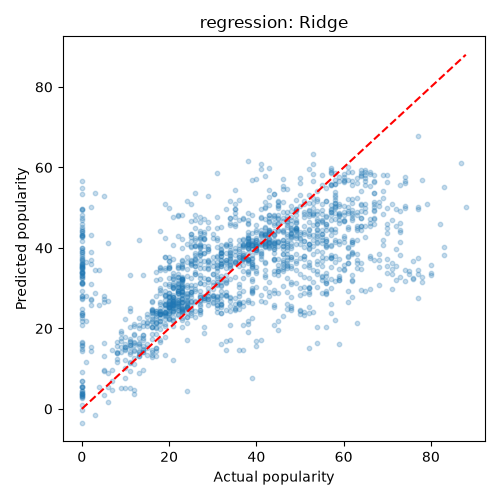

In [3]:
display(Image(filename=str(ctx.path('plots', 'regression_predictions.png'))))

MAE is the average absolute error in popularity points. RMSE penalizes larger errors. R² compares to a mean prediction; values below zero indicate worse performance on this holdout. Within ±5 is a tolerance percentage. We omit the original MAPE because zero popularity makes percentage error unsuitable.